<a href="https://colab.research.google.com/github/devanandravikumarrs-max/Daily-Rainfall-Forecasting/blob/main/Daily_Rainfall_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
# Sequence generation snippet
def create_sequences(data, seq_length=7):
    X, y = [], []
    for i in range(seq_length, len(data)):
        X.append(data[i-seq_length:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

Saving Indian Rainfall Dataset District-wise Daily Measurements.csv to Indian Rainfall Dataset District-wise Daily Measurements (1).csv
Dataset loaded successfully
Total dataset rows: 8790
Selected district: Ernakulam
Monthly records: 12

Daily observations: 365
Date range: 2022-01-01 to 2022-12-31
Missing observations after cleaning: 0

Training sequences: (285, 7, 1)
Testing sequences: (73, 7, 1)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 7, 64)          │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - loss: 0.0245 - mae: 0.0835 - val_loss: 0.0065 - val_mae: 0.0757 - learning_rate: 0.0010
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0211 - mae: 0.1070 - val_loss: 0.0088 - val_mae: 0.0897 - learning_rate: 0.0010
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0207 - mae: 0.1066 - val_loss: 0.0056 - val_mae: 0.0703 - learning_rate: 0.0010
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0187 - mae: 0.0963 - val_loss: 0.0046 - val_mae: 0.0634 - learning_rate: 0.0010
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0183 - mae: 0.0923 - val_loss: 0.0040 - val_mae: 0.0579 - learning_rate: 0.0010
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0182 - mae: 0.0883 - val_loss: 0.0034 - val_mae: 0.0518 - learning_rate: 0.0010
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0179 - mae: 0.0880 - val_loss: 0.0036 - val_mae: 0.0537 - learning_rate: 0.0010
Epoch 

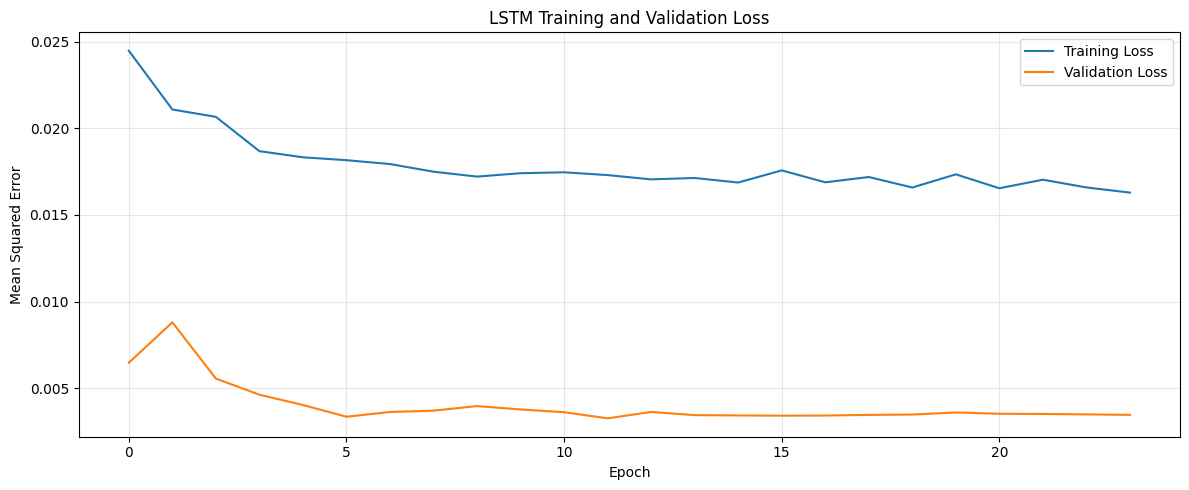

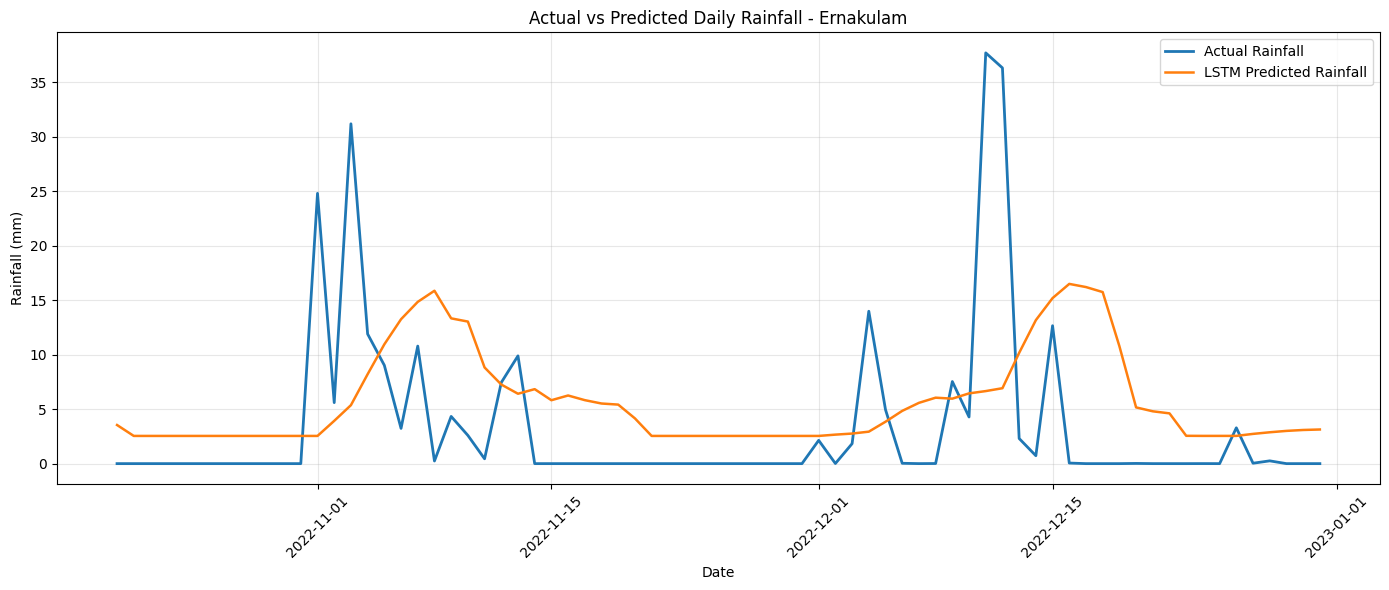

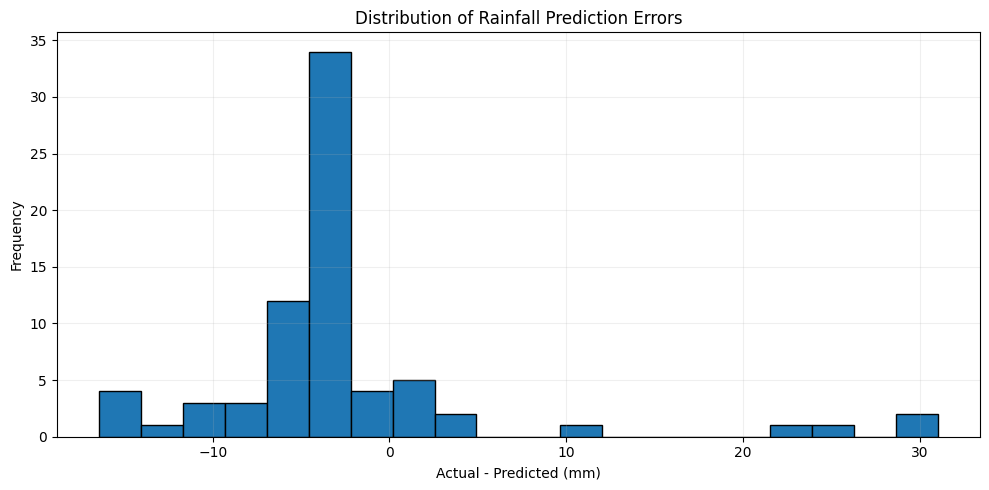


========== NEXT 7 DAYS FORECAST ==========


,Date,Predicted Rainfall (mm)
0,2023-01-01,3.14
1,2023-01-02,3.30
2,2023-01-03,3.09
3,2023-01-04,3.51
4,2023-01-05,3.99
5,2023-01-06,4.58
6,2023-01-07,5.24


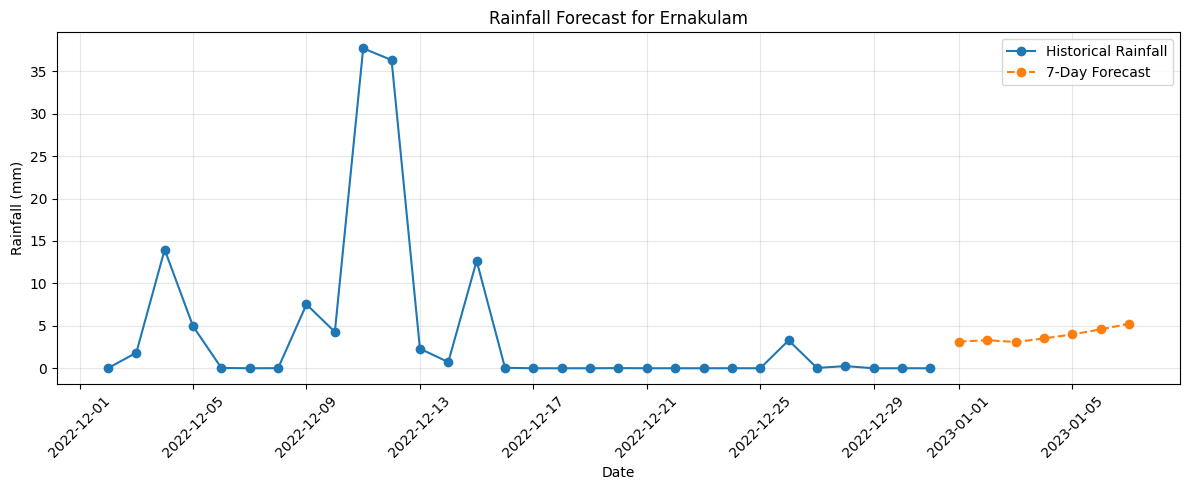


Forecast saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:

# ============================================================
# ADVANCED AI-BASED DAILY RAINFALL FORECASTING SYSTEM
# Dataset: Indian Rainfall Dataset District-wise Daily Measurements
# District: Ernakulam, Kerala
# Model: Stacked LSTM + Dropout + Early Stopping
# ============================================================

import os
import random
import calendar
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# -------------------- 1. CONFIGURATION --------------------

SEED = 42
DISTRICT = "Ernakulam"
YEAR = 2022                 # Placeholder: verify the actual dataset year
SEQ_LENGTH = 7
FORECAST_DAYS = 7
TRAIN_RATIO = 0.80
EPOCHS = 100
BATCH_SIZE = 16

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# -------------------- 2. LOAD DATASET --------------------

from google.colab import files

uploaded = files.upload()
file_path = next(iter(uploaded.keys()))

df = pd.read_csv(file_path, sep=";")
df.columns = df.columns.str.strip()

required_cols = ["district", "month"]
days_cols = [
    "1st", "2nd", "3rd", "4th", "5th", "6th", "7th",
    "8th", "9th", "10th", "11th", "12th", "13th", "14th",
    "15th", "16th", "17th", "18th", "19th", "20th",
    "21st", "22nd", "23rd", "24th", "25th", "26th",
    "27th", "28th", "29th", "30th", "31st"
]

missing_cols = [
    c for c in required_cols + days_cols if c not in df.columns
]
if missing_cols:
    raise ValueError(f"Missing dataset columns: {missing_cols}")

df["district"] = df["district"].astype(str).str.strip()
district_df = df[
    df["district"].str.casefold() == DISTRICT.casefold()
].copy()

if district_df.empty:
    raise ValueError(f"District '{DISTRICT}' was not found.")

print("Dataset loaded successfully")
print("Total dataset rows:", len(df))
print("Selected district:", DISTRICT)
print("Monthly records:", len(district_df))

# -------------------- 3. CONVERT TO DAILY SERIES --------------------

records = []

for _, row in district_df.iterrows():
    month = int(row["month"])

    if not 1 <= month <= 12:
        continue

    days_in_month = calendar.monthrange(YEAR, month)[1]

    for day in range(1, days_in_month + 1):
        col = days_cols[day - 1]
        value = pd.to_numeric(row[col], errors="coerce")

        if pd.notna(value):
            records.append({
                "date": pd.Timestamp(YEAR, month, day),
                "rainfall": float(value)
            })

ts_df = pd.DataFrame(records)
ts_df = (
    ts_df.drop_duplicates("date")
    .sort_values("date")
    .set_index("date")
)

# Reject invalid rainfall values instead of silently accepting them.
if ts_df.empty:
    raise ValueError("No valid daily rainfall observations were found.")

if (ts_df["rainfall"] < 0).any():
    raise ValueError("Negative rainfall values need data correction.")

# Reindex to a complete daily calendar.
# Missing observations remain NaN; they are not assumed to be zero.
full_dates = pd.date_range(
    ts_df.index.min(), ts_df.index.max(), freq="D"
)
ts_df = ts_df.reindex(full_dates)
ts_df.index.name = "date"

# Linear interpolation is used only to fill missing observations.
# For real research, check the dataset's missing-value conventions.
ts_df["rainfall"] = ts_df["rainfall"].interpolate(
    method="time", limit_area="inside"
)

if ts_df["rainfall"].isna().any():
    raise ValueError(
        "Missing values remain at the series boundaries. "
        "Resolve them using the dataset documentation."
    )

print("\nDaily observations:", len(ts_df))
print("Date range:", ts_df.index.min().date(),
      "to", ts_df.index.max().date())
print("Missing observations after cleaning:",
      int(ts_df["rainfall"].isna().sum()))

# -------------------- 4. CHRONOLOGICAL DATA SPLIT --------------------

values = ts_df[["rainfall"]].values.astype(np.float32)

split_idx = int(len(values) * TRAIN_RATIO)

if split_idx <= SEQ_LENGTH or len(values) - split_idx < 2:
    raise ValueError("Not enough observations for this train/test split.")

# Fit scaler only on the training period to prevent leakage.
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(values[:split_idx])
scaled_values = scaler.transform(values)

# -------------------- 5. CREATE SEQUENCES --------------------

def create_sequences(data, seq_length=7):
    X, y, target_indices = [], [], []

    for i in range(seq_length, len(data)):
        X.append(data[i-seq_length:i, 0])
        y.append(data[i, 0])
        target_indices.append(i)

    X = np.asarray(X, dtype=np.float32).reshape(-1, seq_length, 1)
    y = np.asarray(y, dtype=np.float32)
    target_indices = np.asarray(target_indices)

    return X, y, target_indices

X, y, target_indices = create_sequences(
    scaled_values, SEQ_LENGTH
)

train_mask = target_indices < split_idx
test_mask = target_indices >= split_idx

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

if len(X_test) == 0:
    raise ValueError("No test sequences were generated.")

print("\nTraining sequences:", X_train.shape)
print("Testing sequences:", X_test.shape)

# -------------------- 6. BUILD ADVANCED LSTM --------------------

model = Sequential([
    Input(shape=(SEQ_LENGTH, 1)),

    LSTM(64, return_sequences=True),
    Dropout(0.25),

    LSTM(32),
    Dropout(0.20),

    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()

# Keep the last part of the training sequences for validation.
# Do not shuffle time-series training samples.
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-5
)

# -------------------- 7. TRAIN MODEL --------------------

history = model.fit(
    X_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.15,
    shuffle=False,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

print("\nTraining completed.")
print("Epochs executed:", len(history.history["loss"]))

# -------------------- 8. TEST PREDICTIONS --------------------

pred_scaled = model.predict(X_test, verbose=0)

y_test_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

y_pred = scaler.inverse_transform(
    pred_scaled.reshape(-1, 1)
).ravel()

# Rainfall cannot be negative.
y_pred = np.maximum(y_pred, 0)

test_dates = ts_df.index[target_indices[test_mask]]

mae = mean_absolute_error(y_test_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred))
r2 = r2_score(y_test_actual, y_pred)

# Simple baseline: predict the previous day's rainfall.
baseline_scaled = X_test[:, -1, 0].reshape(-1, 1)
baseline_pred = scaler.inverse_transform(baseline_scaled).ravel()

baseline_mae = mean_absolute_error(y_test_actual, baseline_pred)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test_actual, baseline_pred)
)

print("\n========== MODEL EVALUATION ==========")
print(f"LSTM MAE:       {mae:.4f} mm")
print(f"LSTM RMSE:      {rmse:.4f} mm")
print(f"LSTM R²:        {r2:.4f}")
print(f"Baseline MAE:   {baseline_mae:.4f} mm")
print(f"Baseline RMSE:  {baseline_rmse:.4f} mm")

print("\nR² can be negative when predictions perform worse than "
      "predicting the test-set mean.")

# -------------------- 9. TRAINING PERFORMANCE GRAPH --------------------

plt.figure(figsize=(12, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# -------------------- 10. ACTUAL VS PREDICTED RAINFALL --------------------

plt.figure(figsize=(14, 6))
plt.plot(
    test_dates, y_test_actual,
    label="Actual Rainfall", linewidth=2
)
plt.plot(
    test_dates, y_pred,
    label="LSTM Predicted Rainfall",
    linewidth=1.8
)
plt.title(f"Actual vs Predicted Daily Rainfall - {DISTRICT}")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# -------------------- 11. ERROR DISTRIBUTION --------------------

errors = y_test_actual - y_pred

plt.figure(figsize=(10, 5))
plt.hist(errors, bins=20, edgecolor="black")
plt.title("Distribution of Rainfall Prediction Errors")
plt.xlabel("Actual - Predicted (mm)")
plt.ylabel("Frequency")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# -------------------- 12. FORECAST NEXT 7 DAYS --------------------

# Recursive forecasting: each prediction is fed into the next step.
last_sequence = scaled_values[-SEQ_LENGTH:].reshape(
    1, SEQ_LENGTH, 1
).copy()

future_predictions = []

for _ in range(FORECAST_DAYS):
    next_scaled = model.predict(last_sequence, verbose=0)[0, 0]

    next_mm = scaler.inverse_transform(
        np.array([[next_scaled]])
    )[0, 0]

    next_mm = max(0.0, float(next_mm))
    future_predictions.append(next_mm)

    # Convert the non-negative prediction back to scaled space.
    next_scaled_clipped = scaler.transform(
        np.array([[next_mm]])
    )[0, 0]

    new_step = np.array(
        [[[next_scaled_clipped]]], dtype=np.float32
    )
    last_sequence = np.concatenate(
        [last_sequence[:, 1:, :], new_step], axis=1
    )

future_dates = pd.date_range(
    ts_df.index[-1] + pd.Timedelta(days=1),
    periods=FORECAST_DAYS,
    freq="D"
)

forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Predicted Rainfall (mm)": np.round(future_predictions, 2)
})

print("\n========== NEXT 7 DAYS FORECAST ==========")
display(forecast_df)

plt.figure(figsize=(12, 5))
plt.plot(
    ts_df.index[-30:], ts_df["rainfall"].tail(30),
    marker="o", label="Historical Rainfall"
)
plt.plot(
    future_dates, future_predictions,
    marker="o", linestyle="--",
    label="7-Day Forecast"
)
plt.title(f"Rainfall Forecast for {DISTRICT}")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# -------------------- 13. EXPORT FORECAST --------------------

forecast_df.to_csv(
    "Ernakulam_7_Day_Rainfall_Forecast.csv",
    index=False
)

print("\nForecast saved successfully.")

# Optional: download forecast CSV to your computer.
from google.colab import files
files.download("Ernakulam_7_Day_Rainfall_Forecast.csv")
